# Exploratory Data Analysis

This notebook analyzes the cleaned, weather-merged dataset (`market_data_with_weather.csv`). It covers price trends, seasonality, cross-market gaps, volatility, weather correlation, data coverage, price distribution, lag correlation, year-over-year trend, refugee-settlement vs. regular markets, and crop-to-crop relationships.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Market    = "market"
Crop      = "commodity"
Date      = "date"
Price     = "price"
Latitude  = "latitude"
Longitude = "longitude"

data = pd.read_csv("market_data_with_weather.csv")
data[Date] = pd.to_datetime(data[Date])

# The forecastable subset is our 5-market x 6-crop core
core = data[data["forecastable"] == True].copy()

print(f"Full dataset: {data.shape}")
print(f"Core (forecastable) subset: {core.shape}")
print(f"Core markets: {sorted(core[Market].unique())}")
print(f"Core crops: {sorted(core[Crop].unique())}")


Full dataset: (21107, 14)
Core (forecastable) subset: (4333, 14)
Core markets: ['Iganga', 'Jinja', 'Lira', 'Mbarara', 'Owino']
Core crops: ['Beans', 'Cassava Flour', 'Maize (White)', 'Maize Flour', 'Millet', 'Sorghum']


### Building a gap-aware monthly series
The raw data only has rows for months that were actually reported -- if a market-crop pair has a real reporting gap (say, a 5-year stretch with no data), the raw rows simply skip over it. Plotting that directly draws a straight line across the gap, which looks exactly like real (if boring) price movement, but is actually just matplotlib connecting two distant points. `core_monthly` reindexes every (market, crop) series onto a continuous monthly calendar, so genuine gaps show up as `NaN` -- and any chart built from it will correctly show a break in the line instead of quietly bridging it.

In [ ]:
def reindex_monthly(g):
    g = g.set_index(Date).sort_index()
    full_range = pd.date_range(g.index.min(), g.index.max(), freq="MS") + pd.DateOffset(days=14)
    return g.reindex(full_range)

monthly_parts = []
for (mkt, crop), g in core.groupby([Market, Crop]):
    g2 = reindex_monthly(g)
    g2[Market] = mkt
    g2[Crop] = crop
    monthly_parts.append(g2)

core_monthly = pd.concat(monthly_parts)
core_monthly.index.name = Date
core_monthly = core_monthly.reset_index()

n_gap_months = core_monthly[Price].isna().sum()
print(f"core: {len(core)} rows (real data only)")
print(f"core_monthly: {len(core_monthly)} rows (continuous calendar, gaps included)")
print(f"Genuine gap-months revealed: {n_gap_months}")


core: 4333 rows (real data only)
core_monthly: 5492 rows (continuous calendar, gaps included)
Genuine gap-months revealed: 1189


## 1. Price Trends per Crop, per Market
The basic view, and the first sanity check that the cleaned data looks right.

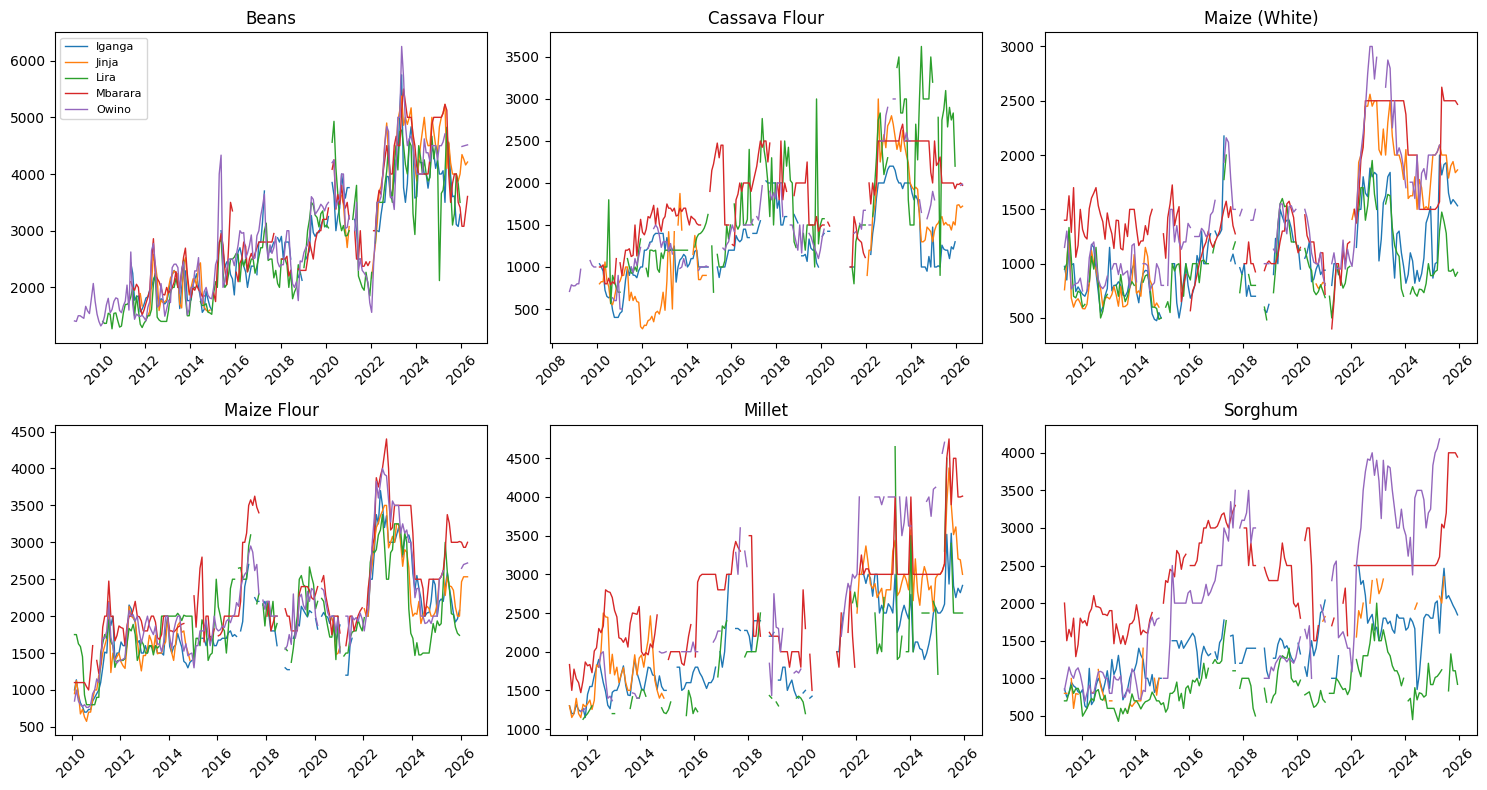

In [ ]:
crops = sorted(core[Crop].unique())
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, crop in zip(axes.flat, crops):
    for mkt, g in core_monthly[core_monthly[Crop] == crop].groupby(Market):
        g = g.sort_values(Date)
        ax.plot(g[Date], g[Price], label=mkt, linewidth=1)
    ax.set_title(crop)
    ax.tick_params(axis='x', rotation=45)

axes.flat[0].legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()


## 2. Seasonality per Crop
Average price by calendar month, across markets, for each crop -- this is what the "best month to sell" advisory and the demand-level indicator are built on.

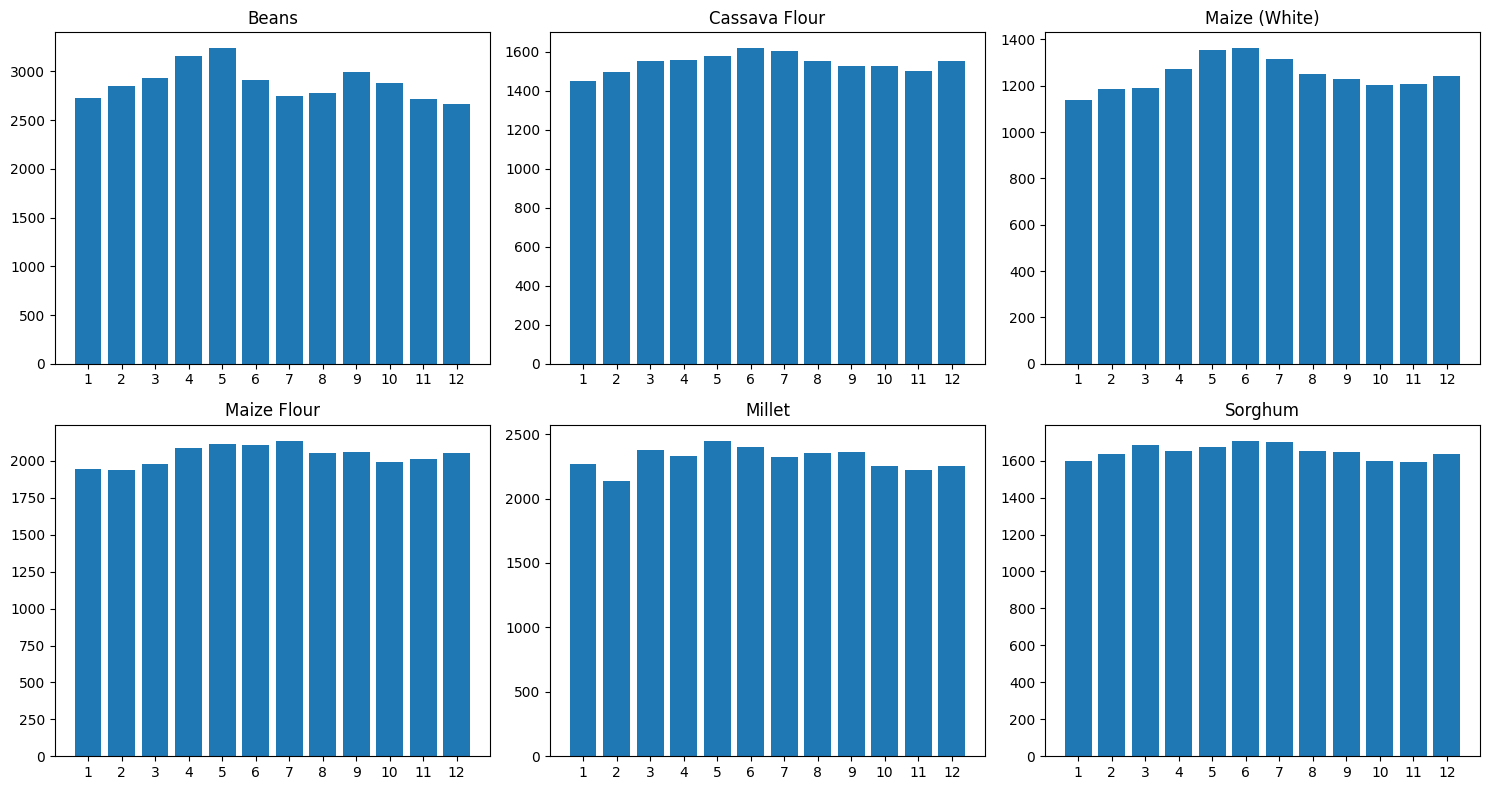

In [ ]:
core['month'] = core[Date].dt.month

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, crop in zip(axes.flat, crops):
    monthly_avg = core[core[Crop] == crop].groupby('month')[Price].mean()
    ax.bar(monthly_avg.index, monthly_avg.values)
    ax.set_title(crop)
    ax.set_xticks(range(1, 13))

plt.tight_layout()
plt.show()


### A closer look: seasonal decomposition for one series
Owino Beans is our deepest series, so it's a good candidate to see trend, seasonal and residual components separated out, rather than just an average-by-month bar chart.

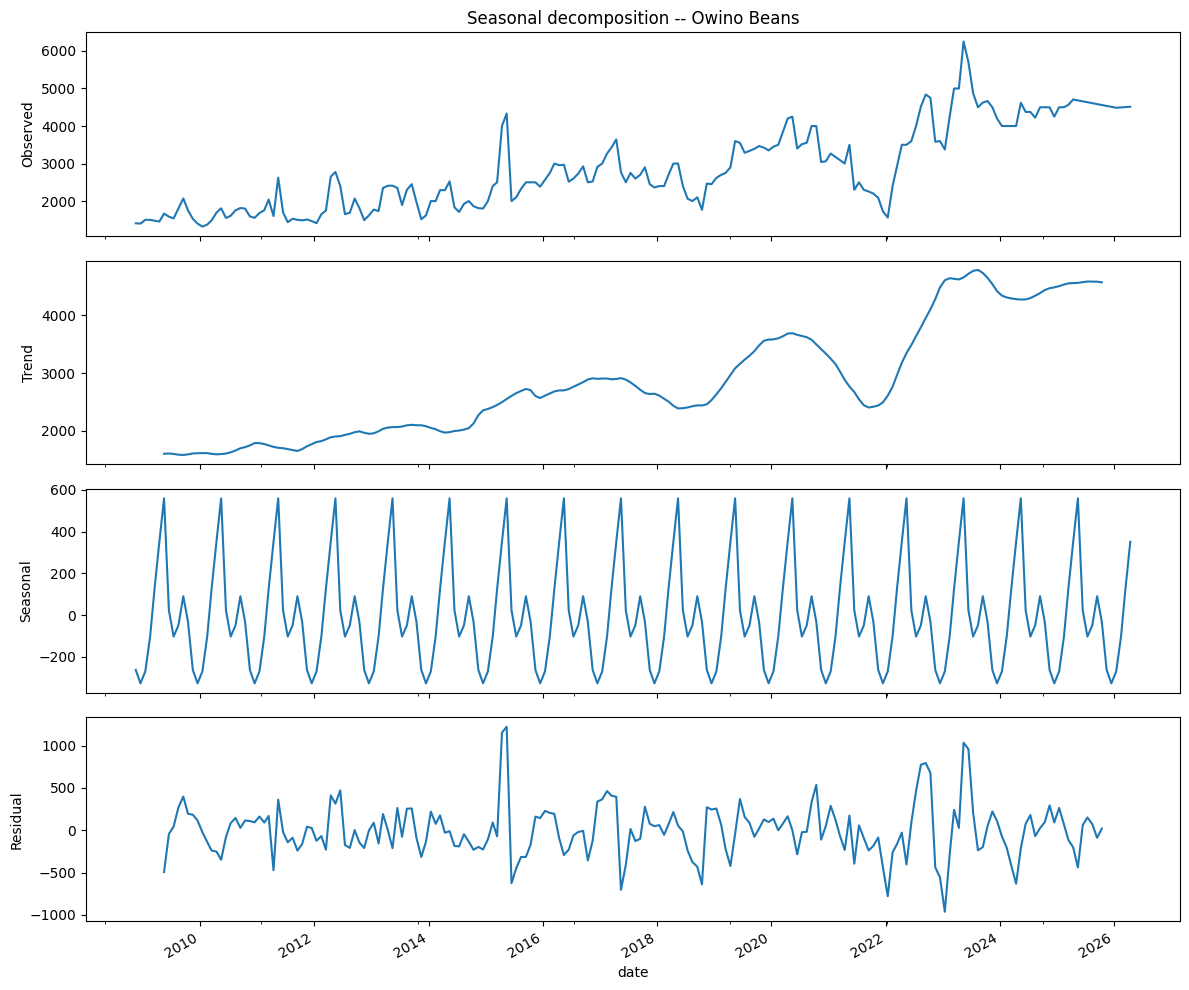

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

series = core_monthly[
    (core_monthly[Market] == 'Owino') & (core_monthly[Crop] == 'Beans')
].set_index(Date)[Price].sort_index()

# Drop leading/trailing NaNs but keep internal ones for the decompose call
series = series.loc[series.first_valid_index():series.last_valid_index()]
# statsmodels needs a complete series -- fill short internal gaps with interpolation
series_filled = series.interpolate(method='time')

result = seasonal_decompose(series_filled, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
result.observed.plot(ax=axes[0]); axes[0].set_ylabel('Observed')
result.trend.plot(ax=axes[1]); axes[1].set_ylabel('Trend')
result.seasonal.plot(ax=axes[2]); axes[2].set_ylabel('Seasonal')
result.resid.plot(ax=axes[3]); axes[3].set_ylabel('Residual')
axes[0].set_title('Seasonal decomposition -- Owino Beans')
plt.tight_layout()
plt.show()


## 3. Cross-Market Price Gaps
For each crop, how much do prices differ across markets in the most recent month?

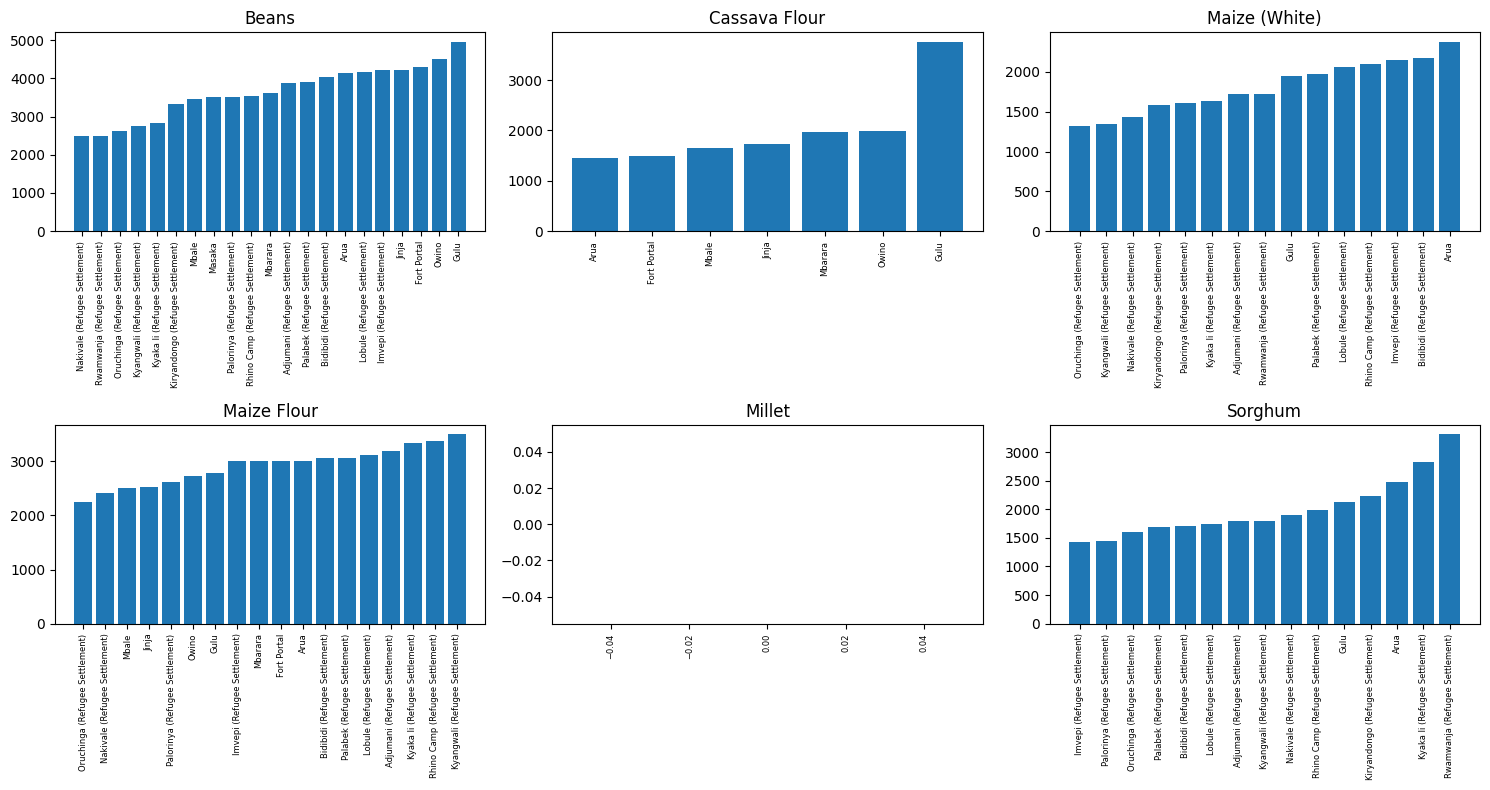


Price gaps as of 2026-04-15, across all markets carrying each crop:
                  min     max  count  pct_gap
commodity                                    
Cassava Flour  1461.0  3760.0      7    157.4
Sorghum        1437.0  3313.0     15    130.5
Beans          2480.0  4956.0     21     99.8
Maize (White)  1325.0  2379.0     15     79.5
Maize Flour    2250.0  3500.0     18     55.6


In [ ]:
wide_core_crops = data[data[Crop].isin(crops)]
latest_month = wide_core_crops[Date].max()
latest = wide_core_crops[wide_core_crops[Date] == latest_month]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, crop in zip(axes.flat, crops):
    sub = latest[latest[Crop] == crop].sort_values(Price)
    ax.bar(sub[Market], sub[Price])
    ax.set_title(crop)
    ax.tick_params(axis='x', rotation=90, labelsize=6)

plt.tight_layout()
plt.show()

gap_summary = latest.groupby(Crop)[Price].agg(['min', 'max', 'count'])
gap_summary['pct_gap'] = round(100 * (gap_summary['max'] - gap_summary['min']) / gap_summary['min'], 1)
print(f"\nPrice gaps as of {latest_month.date()}, across all markets carrying each crop:")
print(gap_summary.sort_values('pct_gap', ascending=False))


## 4. Price Volatility per Series
Volatility is included here as a descriptive statistic.

 market     commodity  avg_volatility
  Owino         Beans      328.345131
  Jinja         Beans      320.371270
   Lira         Beans      317.941200
   Lira Cassava Flour      288.172211
   Lira        Millet      281.674866
 Iganga         Beans      274.941338
Mbarara         Beans      249.257646
  Owino       Sorghum      248.899322
  Jinja        Millet      236.004246
Mbarara        Millet      226.285012
   Lira   Maize Flour      219.562771
  Jinja   Maize Flour      205.099460
Mbarara   Maize Flour      200.855184
  Owino   Maize Flour      183.202367
  Jinja Cassava Flour      181.948960
 Iganga Maize (White)      176.603435
  Owino        Millet      172.159210
 Iganga        Millet      164.910018
 Iganga   Maize Flour      163.539316
Mbarara       Sorghum      162.578475
  Owino Maize (White)      157.817358
 Iganga       Sorghum      156.566409
Mbarara Maize (White)      154.509044
  Jinja Maize (White)      153.928499
  Jinja       Sorghum      149.618985
   Lira Maiz

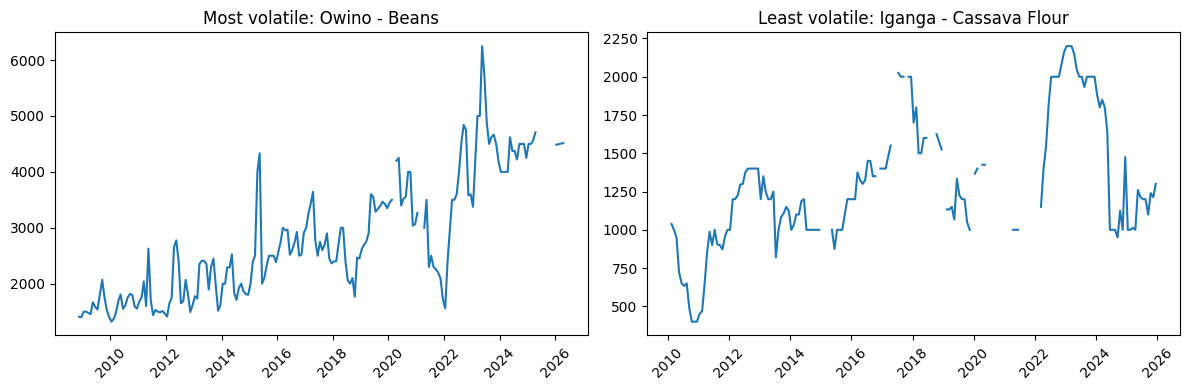

In [ ]:
volatility_rows = []
for (mkt, crop), g in core_monthly.groupby([Market, Crop]):
    g = g.sort_values(Date)
    rolling_std = g[Price].rolling(6, min_periods=3).std()
    volatility_rows.append({Market: mkt, Crop: crop, 'avg_volatility': rolling_std.mean()})

volatility_df = pd.DataFrame(volatility_rows).sort_values('avg_volatility', ascending=False)
print(volatility_df.to_string(index=False))

most_volatile = volatility_df.iloc[0]
least_volatile = volatility_df.iloc[-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, row, title in zip(axes, [most_volatile, least_volatile], ['Most volatile', 'Least volatile']):
    g = core_monthly[(core_monthly[Market] == row[Market]) & (core_monthly[Crop] == row[Crop])].sort_values(Date)
    ax.plot(g[Date], g[Price])
    ax.set_title(f"{title}: {row[Market]} - {row[Crop]}")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## 5. Weather-Price Correlation
Does rainfall actually move price for each crop? Checked directly rather than assumed.

    commodity  corr_same_month_rainfall  corr_rainfall_lag1
        Beans                     0.196               0.151
Cassava Flour                     0.016               0.136
Maize (White)                     0.076               0.120
  Maize Flour                     0.095               0.142
       Millet                     0.043               0.051
      Sorghum                     0.053               0.062


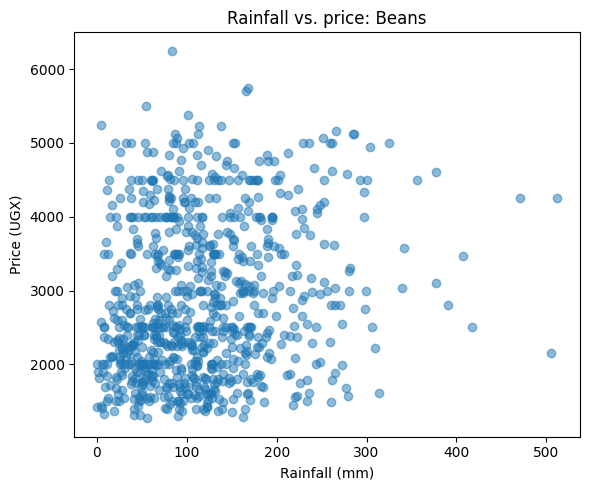

In [ ]:
weather_corr_rows = []
for crop, g in core.groupby(Crop):
    same_month = g[Price].corr(g['rainfall_mm'])
    weather_corr_rows.append({Crop: crop, 'corr_same_month_rainfall': round(same_month, 3)})

lag_rows = []
for (mkt, crop), g in core_monthly.groupby([Market, Crop]):
    g = g.sort_values(Date)
    lagged = g[Price].corr(g['rainfall_mm'].shift(1))
    lag_rows.append({Crop: crop, 'corr_rainfall_lag1': lagged})
lag_df = pd.DataFrame(lag_rows).groupby(Crop)['corr_rainfall_lag1'].mean().round(3)

weather_corr_df = pd.DataFrame(weather_corr_rows).set_index(Crop)
weather_corr_df['corr_rainfall_lag1'] = lag_df
weather_corr_df = weather_corr_df.reset_index()
print(weather_corr_df.to_string(index=False))

strongest = weather_corr_df.reindex(
    weather_corr_df['corr_same_month_rainfall'].abs().sort_values(ascending=False).index
).iloc[0][Crop]

fig, ax = plt.subplots(figsize=(6, 5))
sub = core[core[Crop] == strongest]
ax.scatter(sub['rainfall_mm'], sub[Price], alpha=0.5)
ax.set_xlabel('Rainfall (mm)')
ax.set_ylabel('Price (UGX)')
ax.set_title(f'Rainfall vs. price: {strongest}')
plt.tight_layout()
plt.show()


## 6. Missing Data & Coverage Recap
How many consecutive months of real data does each market-crop pair actually have? This explains why some pairs are trustworthy for forecasting and others aren't.

 market     commodity  months_in_range  max_consecutive_valid
  Jinja       Sorghum              175                      8
   Lira        Millet              176                      8
  Owino        Millet              163                      9
  Owino Cassava Flour              211                     11
  Owino Maize (White)              168                     21
   Lira Maize (White)              176                     22
   Lira Cassava Flour              189                     23
 Iganga         Beans              176                     46
 Iganga       Sorghum              176                     46
 Iganga Maize (White)              176                     46
 Iganga        Millet              176                     46
Mbarara        Millet              176                     47
Mbarara       Sorghum              176                     47
Mbarara Maize (White)              176                     47
  Jinja        Millet              176                     48
  Jinja 

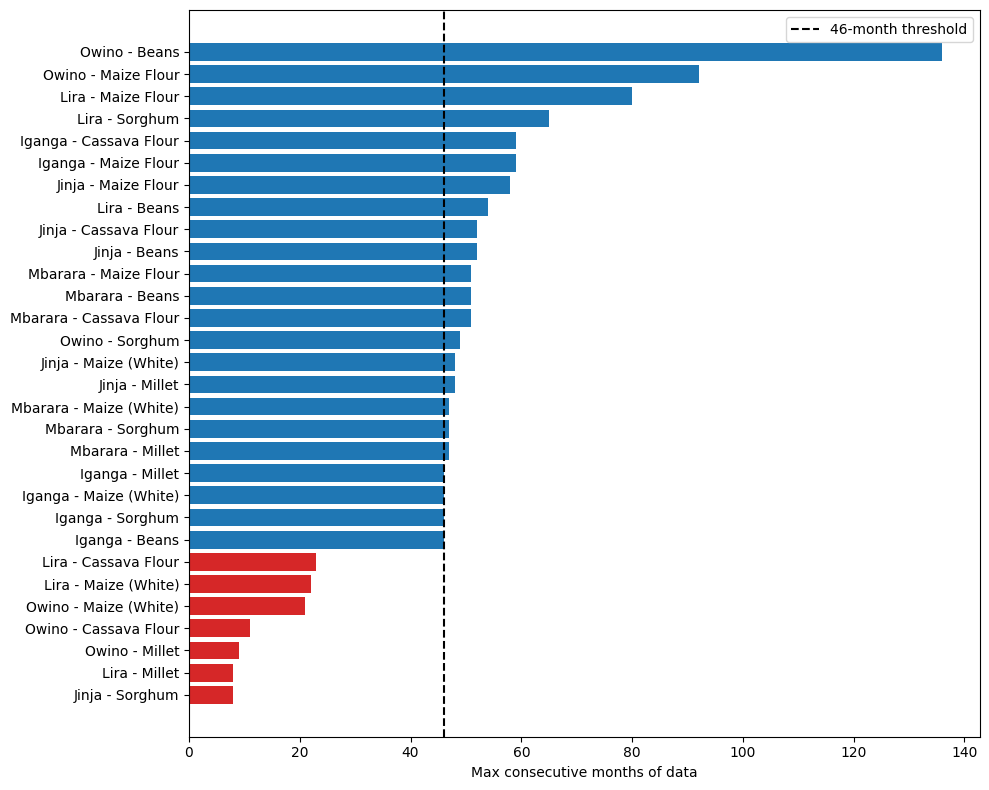

In [ ]:
def max_consecutive_months(s):
    is_val = s.notna()
    run_id = (is_val != is_val.shift()).cumsum()
    best = 0
    for rid, run in is_val.groupby(run_id):
        if run.iloc[0]:
            best = max(best, len(run))
    return best

coverage_rows = []
for (mkt, crop), g in core.groupby([Market, Crop]):
    g = g.set_index(Date).sort_index()
    full_range = pd.date_range(g.index.min(), g.index.max(), freq="MS") + pd.DateOffset(days=14)
    g = g.reindex(full_range)
    coverage_rows.append({
        Market: mkt, Crop: crop,
        "months_in_range": len(g),
        "max_consecutive_valid": max_consecutive_months(g[Price]),
    })

coverage_df = pd.DataFrame(coverage_rows).sort_values("max_consecutive_valid")
print(coverage_df.to_string(index=False))

THRESHOLD = 46  # the forecastable-series threshold agreed for this project
fig, ax = plt.subplots(figsize=(10, 8))
labels = coverage_df[Market] + " - " + coverage_df[Crop]
colors = ['tab:red' if v < THRESHOLD else 'tab:blue' for v in coverage_df['max_consecutive_valid']]
ax.barh(labels, coverage_df['max_consecutive_valid'], color=colors)
ax.axvline(THRESHOLD, color='black', linestyle='--', label=f'{THRESHOLD}-month threshold')
ax.legend()
ax.set_xlabel('Max consecutive months of data')
plt.tight_layout()
plt.show()


### 6b. Coverage Beyond the Core -- Expansion Candidates
This checks which market-crop pairs *outside* the current 5-market core also clear the 46-month forecastability threshold.

In [ ]:
def max_consecutive_months(s):
    is_val = s.notna()
    run_id = (is_val != is_val.shift()).cumsum()
    best = 0
    for rid, run in is_val.groupby(run_id):
        if run.iloc[0]:
            best = max(best, len(run))
    return best

wide_core_crops = data[data[Crop].isin(crops)]
expansion_rows = []
for (mkt, crop), g in wide_core_crops.groupby([Market, Crop]):
    g = g.set_index(Date).sort_index()
    full_range = pd.date_range(g.index.min(), g.index.max(), freq="MS") + pd.DateOffset(days=14)
    g = g.reindex(full_range)
    expansion_rows.append({
        Market: mkt, Crop: crop,
        'max_consecutive_months': max_consecutive_months(g[Price]),
        'is_refugee_settlement': 'Refugee' in mkt,
        'already_in_core': mkt in core[Market].unique(),
    })

expansion_df = pd.DataFrame(expansion_rows)
THRESHOLD = 46
candidates = expansion_df[
    (expansion_df['max_consecutive_months'] >= THRESHOLD) & (~expansion_df['already_in_core'])
].sort_values('max_consecutive_months', ascending=False)

print(f"Market-crop pairs outside the current core that clear the {THRESHOLD}-month threshold: {len(candidates)}")
print(f"Of those, refugee-settlement pairs: {candidates['is_refugee_settlement'].sum()}")
print()
print(candidates.to_string(index=False))


Market-crop pairs outside the current core that clear the 46-month threshold: 49
Of those, refugee-settlement pairs: 44

                          market     commodity  max_consecutive_months  is_refugee_settlement  already_in_core
   Adjumani (Refugee Settlement)         Beans                      64                   True            False
   Adjumani (Refugee Settlement) Maize (White)                      64                   True            False
   Adjumani (Refugee Settlement)   Maize Flour                      64                   True            False
   Bidibidi (Refugee Settlement)         Beans                      64                   True            False
   Bidibidi (Refugee Settlement)   Maize Flour                      64                   True            False
     Imvepi (Refugee Settlement)         Beans                      64                   True            False
   Bidibidi (Refugee Settlement)       Sorghum                      64                   True         

## 7. Distribution of Prices per Crop
Useful for spotting whether the outlier threshold used during cleaning looks reasonable, and for describing the data in the write-up.

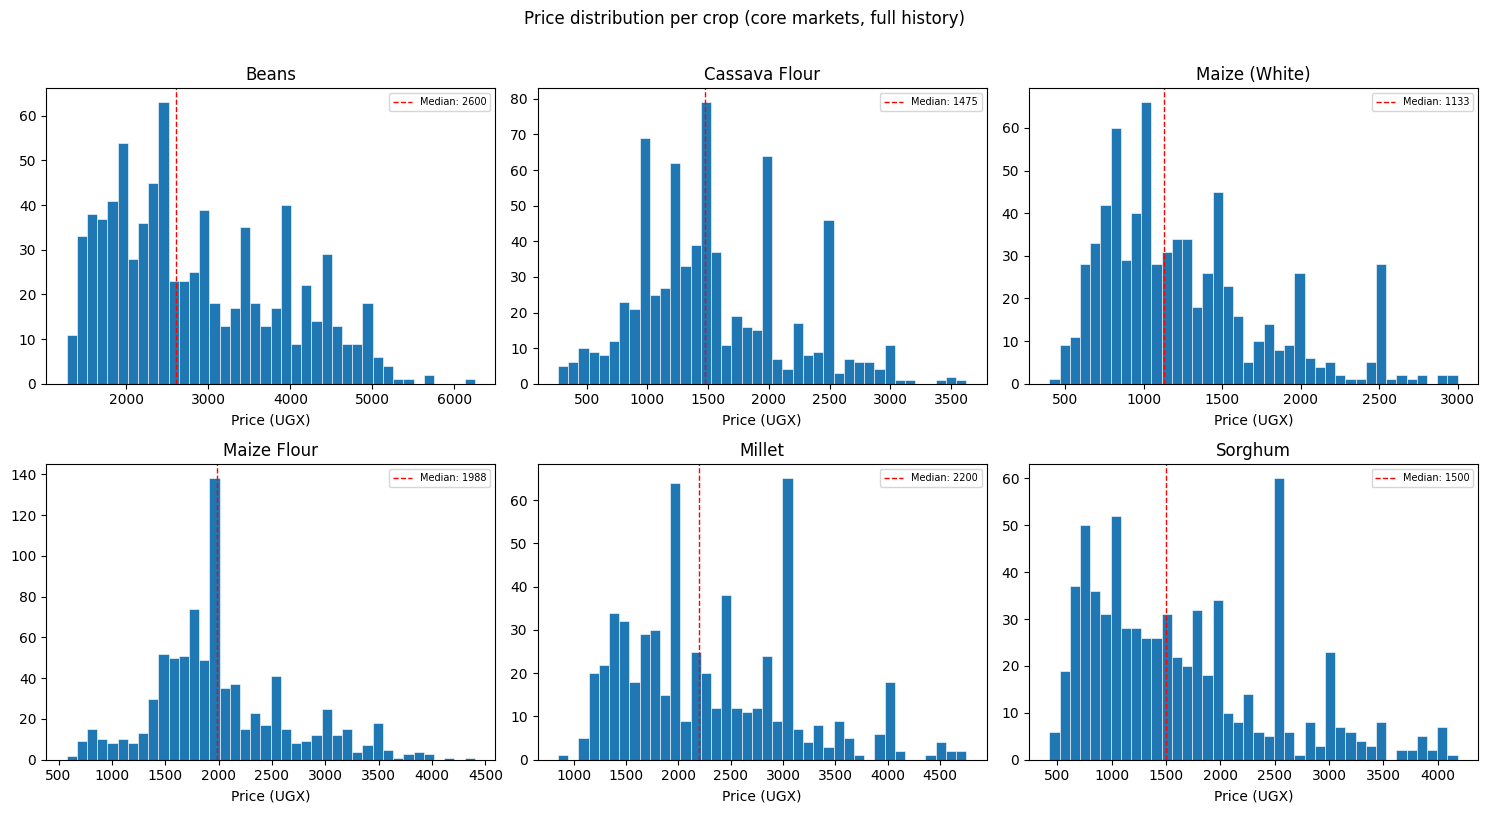

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, crop in zip(axes.flat, crops):
    prices = core[core[Crop] == crop][Price].dropna()
    ax.hist(prices, bins=40, edgecolor='white', linewidth=0.4)
    ax.axvline(prices.median(), color='red', linestyle='--', linewidth=1, label=f'Median: {prices.median():.0f}')
    ax.set_title(crop)
    ax.set_xlabel('Price (UGX)')
    ax.legend(fontsize=7)

plt.suptitle('Price distribution per crop (core markets, full history)', y=1.01)
plt.tight_layout()
plt.show()


## 8. Lagged Price Correlation
How strongly does last month's price predict this month's? This previews whether the `price_lag1` feature will actually carry predictive power before modeling.

 market     commodity  corr_with_lag1
   Lira        Millet        0.692075
   Lira Cassava Flour        0.793233
 Iganga Maize (White)        0.818723
   Lira       Sorghum        0.859697
Mbarara        Millet        0.879556
   Lira Maize (White)        0.885326
 Iganga       Sorghum        0.898353
   Lira   Maize Flour        0.902326
 Iganga        Millet        0.919137
   Lira         Beans        0.919665
Mbarara Cassava Flour        0.927262
  Jinja        Millet        0.928747
  Owino         Beans        0.930417
 Iganga         Beans        0.931597
Mbarara Maize (White)        0.932286
Mbarara       Sorghum        0.940334
  Owino Maize (White)        0.941782
  Jinja Cassava Flour        0.944599
  Jinja       Sorghum        0.947221
Mbarara   Maize Flour        0.947840
  Jinja   Maize Flour        0.951130
 Iganga Cassava Flour        0.954160
  Owino   Maize Flour        0.954995
  Owino        Millet        0.956310
 Iganga   Maize Flour        0.958286
  Jinja Maiz

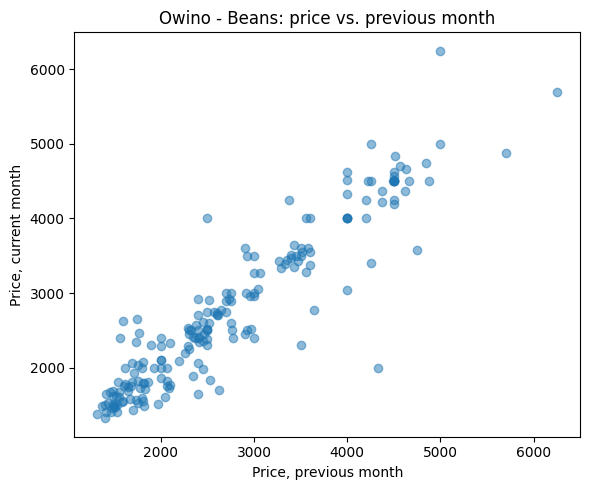

In [ ]:
# Uses core_monthly so shift(1) correctly means "previous calendar month"
# instead of "previous row that happened to have data".
lag_corr_rows = []
for (mkt, crop), g in core_monthly.groupby([Market, Crop]):
    g = g.sort_values(Date)
    lag1 = g[Price].shift(1)
    lag_corr_rows.append({Market: mkt, Crop: crop, 'corr_with_lag1': g[Price].corr(lag1)})

lag_corr_df = pd.DataFrame(lag_corr_rows).sort_values('corr_with_lag1')
print(lag_corr_df.to_string(index=False))
print(f"\nAverage lag-1 correlation across all series: {lag_corr_df['corr_with_lag1'].mean():.3f}")

example = core_monthly[(core_monthly[Market] == 'Owino') & (core_monthly[Crop] == 'Beans')].sort_values(Date)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(example[Price].shift(1), example[Price], alpha=0.5)
ax.set_xlabel('Price, previous month')
ax.set_ylabel('Price, current month')
ax.set_title('Owino - Beans: price vs. previous month')
plt.tight_layout()
plt.show()


## 9. Year-over-Year Price Trend
Has the general price level drifted upward over 2006-2026? Matters because a long-term trend on top of the seasonal pattern can affect how the model should be validated.

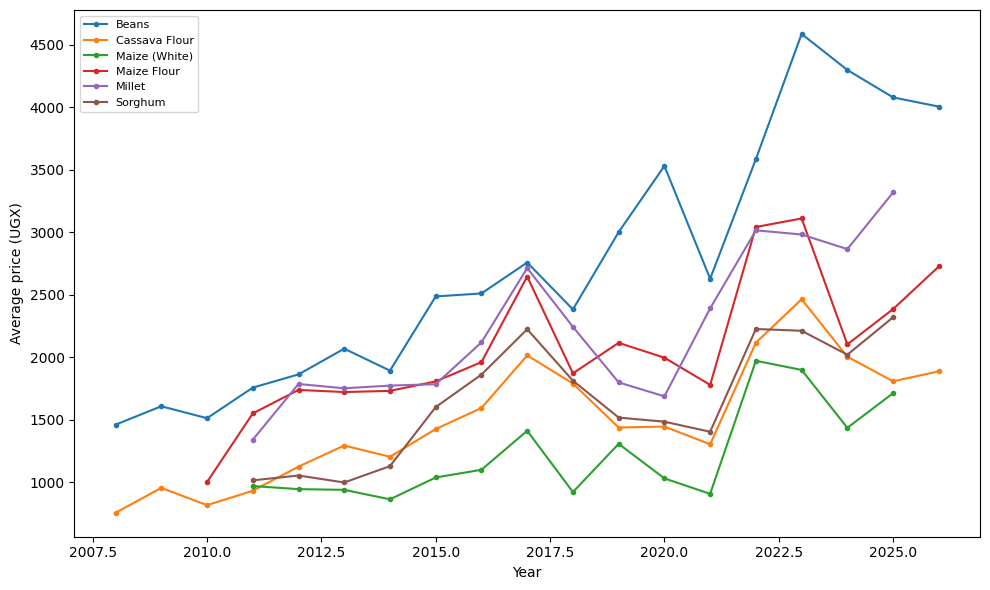

In [ ]:
core['year'] = core[Date].dt.year
yoy = core.groupby([Crop, 'year'])[Price].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
for crop, g in yoy.groupby(Crop):
    ax.plot(g['year'], g[Price], marker='o', label=crop, markersize=3)

ax.set_xlabel('Year')
ax.set_ylabel('Average price (UGX)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 10. Refugee-Settlement vs. Regular Market Comparison


Refugee-settlement rows: 9314
Crops in refugee-settlement markets: ['Beans', 'Cassava (Fresh)', 'Charcoal', 'Firewood', 'Fish (Dry)', 'Laundry Soap', 'Leafy Vegetables', 'Maize (White)', 'Maize Flour', 'Millet Flour', 'Nails', 'Salt', 'Sorghum']
Crops in regular markets: ['Beans', 'Cassava Flour', 'Maize', 'Maize (White)', 'Maize Flour', 'Millet', 'Plantains', 'Sorghum']
Crops common to both: ['Beans', 'Maize (White)', 'Maize Flour', 'Sorghum']
               regular_market_avg  refugee_settlement_avg  pct_diff
commodity                                                          
Beans                 3280.772037             3168.808127      -3.4
Maize (White)         1307.375311             1412.521242       8.0
Maize Flour           2265.303109             2727.630943      20.4
Sorghum               1644.044654             1776.287759       8.0


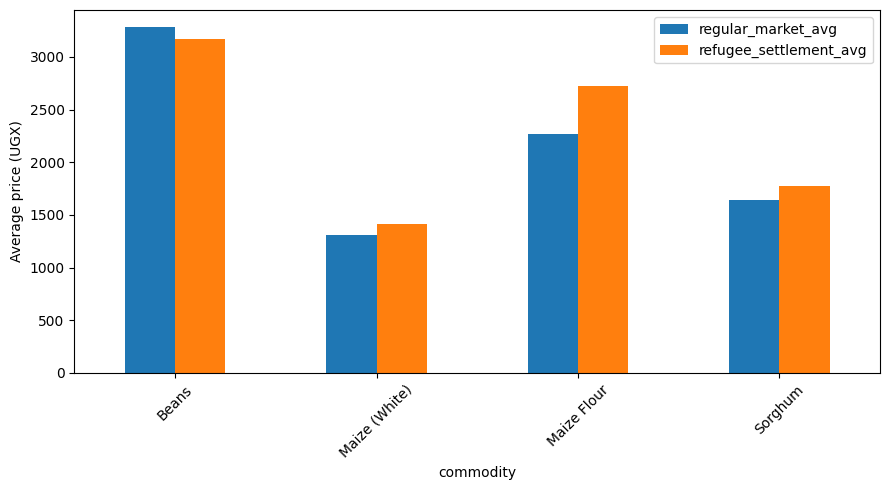

In [ ]:
data['is_refugee'] = data[Market].str.contains('refugee', case=False, na=False)

n_refugee_rows = data['is_refugee'].sum()
refugee_crops = set(data.loc[data['is_refugee'], Crop].unique())
regular_crops = set(data.loc[~data['is_refugee'], Crop].unique())
common_crops = sorted(refugee_crops & regular_crops)

print(f"Refugee-settlement rows: {n_refugee_rows}")
print(f"Crops in refugee-settlement markets: {sorted(refugee_crops)}")
print(f"Crops in regular markets: {sorted(regular_crops)}")
print(f"Crops common to both: {common_crops}")

if n_refugee_rows == 0:
    print("\nNo refugee-settlement rows found in this dataset -- nothing to compare.")
    print("Check that 'market' values still contain '(refugee settlement)' at this point in the pipeline.")
elif not common_crops:
    print("\nNo crop names are shared between the two groups -- likely a naming mismatch")
    print("(e.g. 'Millet' in regular markets vs 'Millet Flour' only in refugee markets).")
    print("Compare the two crop lists printed above to see exactly where they diverge.")
else:
    comparison = data[data[Crop].isin(common_crops)].groupby([Crop, 'is_refugee'])[Price].mean().unstack()
    comparison.columns = ['regular_market_avg', 'refugee_settlement_avg']
    comparison['pct_diff'] = round(100 * (comparison['refugee_settlement_avg'] - comparison['regular_market_avg']) / comparison['regular_market_avg'], 1)
    print(comparison)

    fig, ax = plt.subplots(figsize=(9, 5))
    comparison[['regular_market_avg', 'refugee_settlement_avg']].plot(kind='bar', ax=ax)
    ax.set_ylabel('Average price (UGX)')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

## 11. Crop-to-Crop Price Relationships
Do related crops (e.g. Maize (White) and Maize Flour) move together, as expected? A quick correlation check adds credibility without being essential to any single feature.

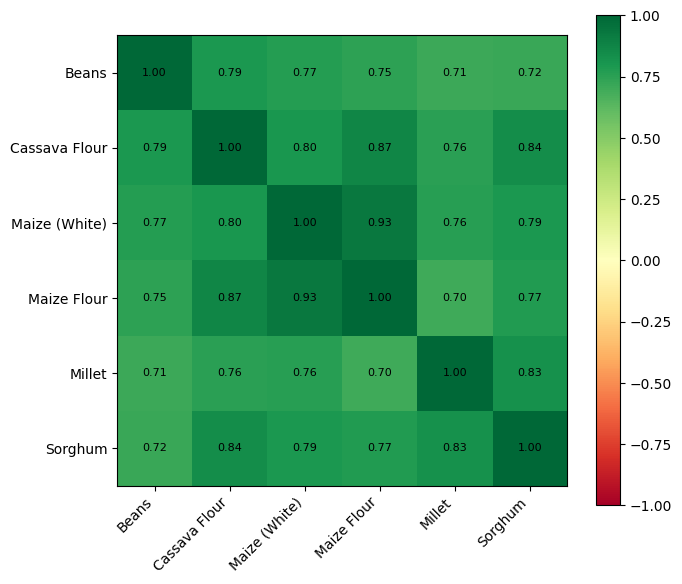

In [ ]:
pivot = core.pivot_table(index=Date, columns=Crop, values=Price, aggfunc='mean')
crop_corr = pivot.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(crop_corr, cmap='RdYlGn', vmin=-1, vmax=1)
ax.set_xticks(range(len(crop_corr.columns)))
ax.set_xticklabels(crop_corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(crop_corr.columns)))
ax.set_yticklabels(crop_corr.columns)
for i in range(len(crop_corr)):
    for j in range(len(crop_corr)):
        ax.text(j, i, f"{crop_corr.iloc[i,j]:.2f}", ha='center', va='center', fontsize=8)
plt.colorbar(im)
plt.tight_layout()
plt.show()


## 14. Dataset Composition
How the full dataset breaks down useful context for the report, showing how much data sits outside the 5-market forecasting core.

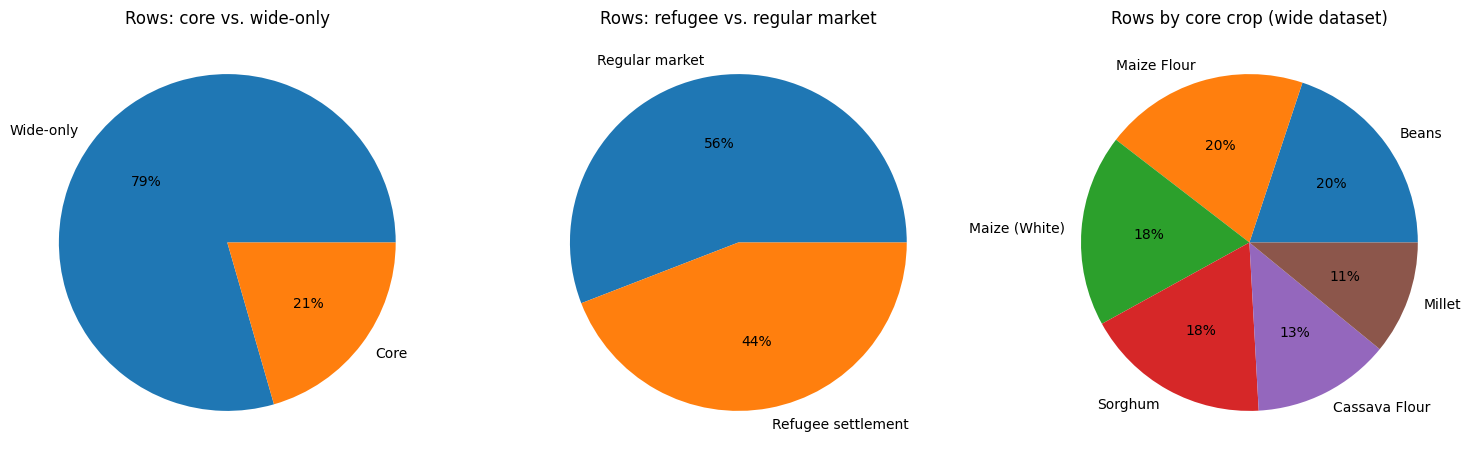

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

forecast_share = data['forecastable'].value_counts()
axes[0].pie(forecast_share, labels=forecast_share.index.map({True: 'Core', False: 'Wide-only'}),
            autopct='%1.0f%%')
axes[0].set_title('Rows: core vs. wide-only')

refugee_share = data['is_refugee'].value_counts()
axes[1].pie(refugee_share, labels=refugee_share.index.map({True: 'Refugee settlement', False: 'Regular market'}),
            autopct='%1.0f%%')
axes[1].set_title('Rows: refugee vs. regular market')

crop_share = data[data[Crop].isin(crops)][Crop].value_counts()
axes[2].pie(crop_share, labels=crop_share.index, autopct='%1.0f%%')
axes[2].set_title('Rows by core crop (wide dataset)')

plt.tight_layout()
plt.show()


## 15. Best Month to Sell -- Market Advisory
A direct preview of the dashboard's seasonal advisory: for every core market-crop pair, which calendar month has historically had the highest average price.

In [ ]:
import calendar

core['month'] = core[Date].dt.month
monthly_averages = core.groupby([Market, Crop, 'month'])[Price].mean().reset_index()
best_months = monthly_averages.loc[monthly_averages.groupby([Market, Crop])[Price].idxmax()]
best_months = best_months.sort_values([Market, Crop])
best_months['month_name'] = best_months['month'].apply(lambda x: calendar.month_name[x])

for _, row in best_months.iterrows():
    print(f"Market: {row[Market]:<10} | Crop: {row[Crop]:<15} | "
          f"Best month: {row['month_name']:<10} | Avg price: {row[Price]:.0f} UGX")


Market: Iganga     | Crop: Beans           | Best month: May        | Avg price: 3151 UGX
Market: Iganga     | Crop: Cassava Flour   | Best month: December   | Avg price: 1383 UGX
Market: Iganga     | Crop: Maize (White)   | Best month: June       | Avg price: 1204 UGX
Market: Iganga     | Crop: Maize Flour     | Best month: July       | Avg price: 1999 UGX
Market: Iganga     | Crop: Millet          | Best month: March      | Avg price: 2113 UGX
Market: Iganga     | Crop: Sorghum         | Best month: March      | Avg price: 1530 UGX
Market: Jinja      | Crop: Beans           | Best month: May        | Avg price: 3626 UGX
Market: Jinja      | Crop: Cassava Flour   | Best month: December   | Avg price: 1415 UGX
Market: Jinja      | Crop: Maize (White)   | Best month: July       | Avg price: 1512 UGX
Market: Jinja      | Crop: Maize Flour     | Best month: June       | Avg price: 2097 UGX
Market: Jinja      | Crop: Millet          | Best month: May        | Avg price: 2569 UGX
Market: Ji

## 16. Price vs. Rainfall

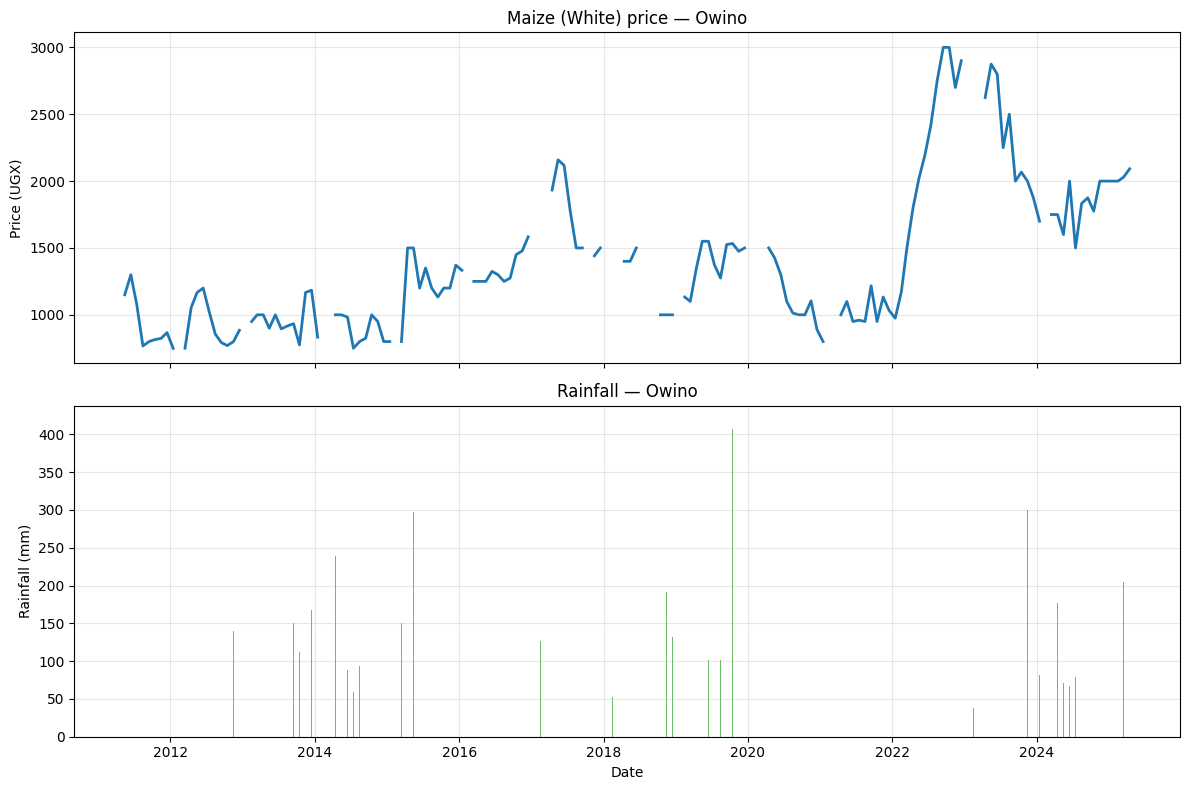

In [ ]:
market_pick, crop_pick_b = 'Owino', 'Maize (White)'
series = core_monthly[
    (core_monthly[Market] == market_pick) & (core_monthly[Crop] == crop_pick_b)
].sort_values(Date)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(series[Date], series[Price], color='tab:blue', linewidth=2, label='Price')
ax1.set_ylabel('Price (UGX)')
ax1.set_title(f'{crop_pick_b} price — {market_pick}')
ax1.grid(True, alpha=0.3)

ax2.bar(series[Date], series['rainfall_mm'], color='tab:green', alpha=0.7, label='Rainfall')
ax2.set_ylabel('Rainfall (mm)')
ax2.set_xlabel('Date')
ax2.set_title(f'Rainfall — {market_pick}')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 17. Cross-Market Price Trend -- Full Timeline
How one crop's price has moved across all 5 core markets over the entire period

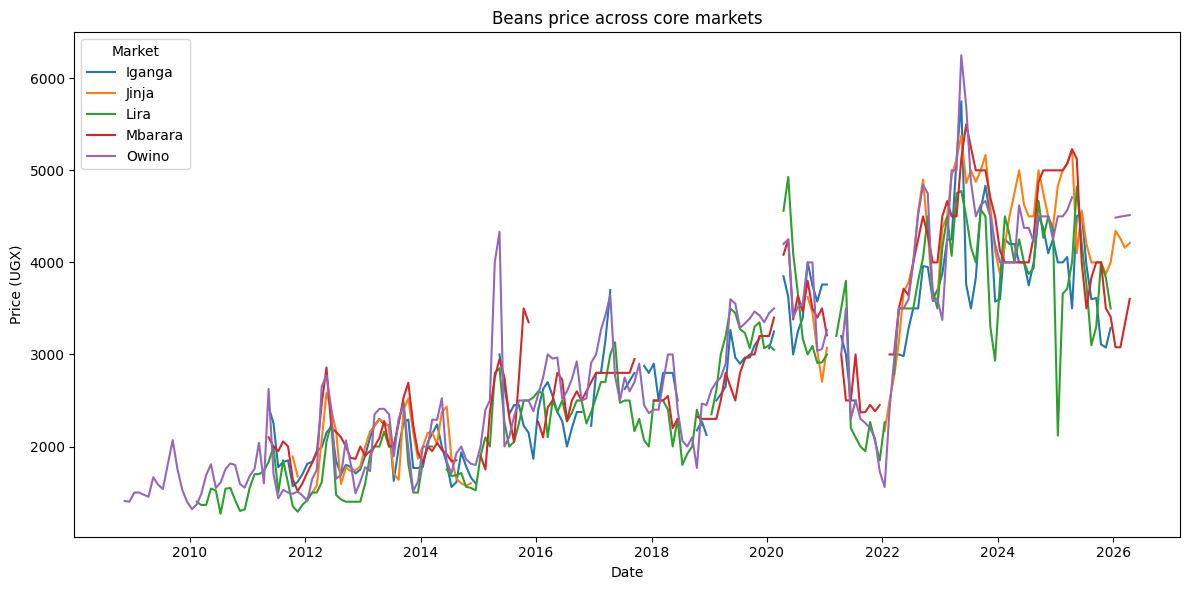

In [ ]:
crop_pick_c = 'Beans'

fig, ax = plt.subplots(figsize=(12, 6))
for mkt, g in core_monthly[core_monthly[Crop] == crop_pick_c].groupby(Market):
    g = g.sort_values(Date)
    ax.plot(g[Date], g[Price], label=mkt, linewidth=1.5)

ax.set_xlabel('Date')
ax.set_ylabel('Price (UGX)')
ax.set_title(f'{crop_pick_c} price across core markets')
ax.legend(title='Market')
plt.tight_layout()
plt.show()


## 18. Weather Correlation by Crop -- Heatmap


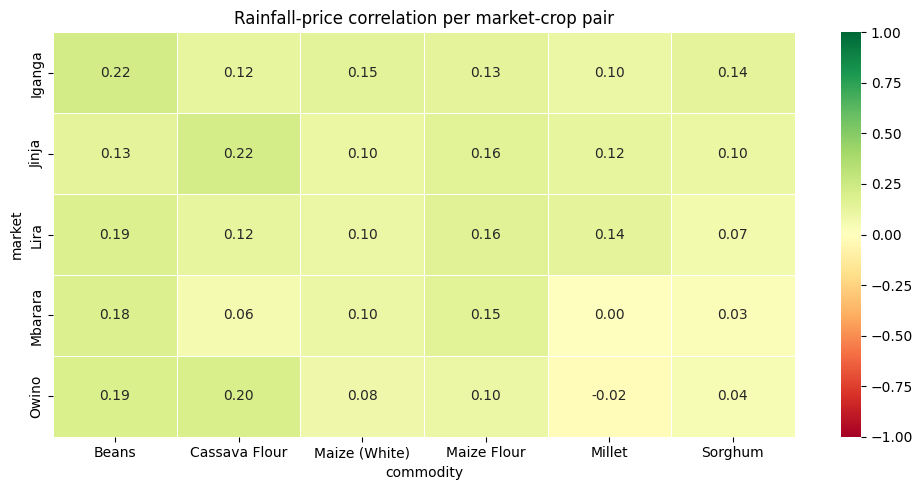

In [ ]:
import seaborn as sns

corr_rows = []
for crop, g in core.groupby(Crop):
    for mkt, gm in g.groupby(Market):
        corr = gm[Price].corr(gm['rainfall_mm'])
        corr_rows.append({Crop: crop, Market: mkt, 'corr': round(corr, 3)})

weather_corr_wide = (
    pd.DataFrame(corr_rows)
    .pivot(index=Market, columns=Crop, values='corr')
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    weather_corr_wide, annot=True, fmt='.2f', cmap='RdYlGn',
    vmin=-1, vmax=1, linewidths=0.5, ax=ax
)
ax.set_title('Rainfall-price correlation per market-crop pair')
plt.tight_layout()
plt.show()


## 19. Seasonality Across All Markets


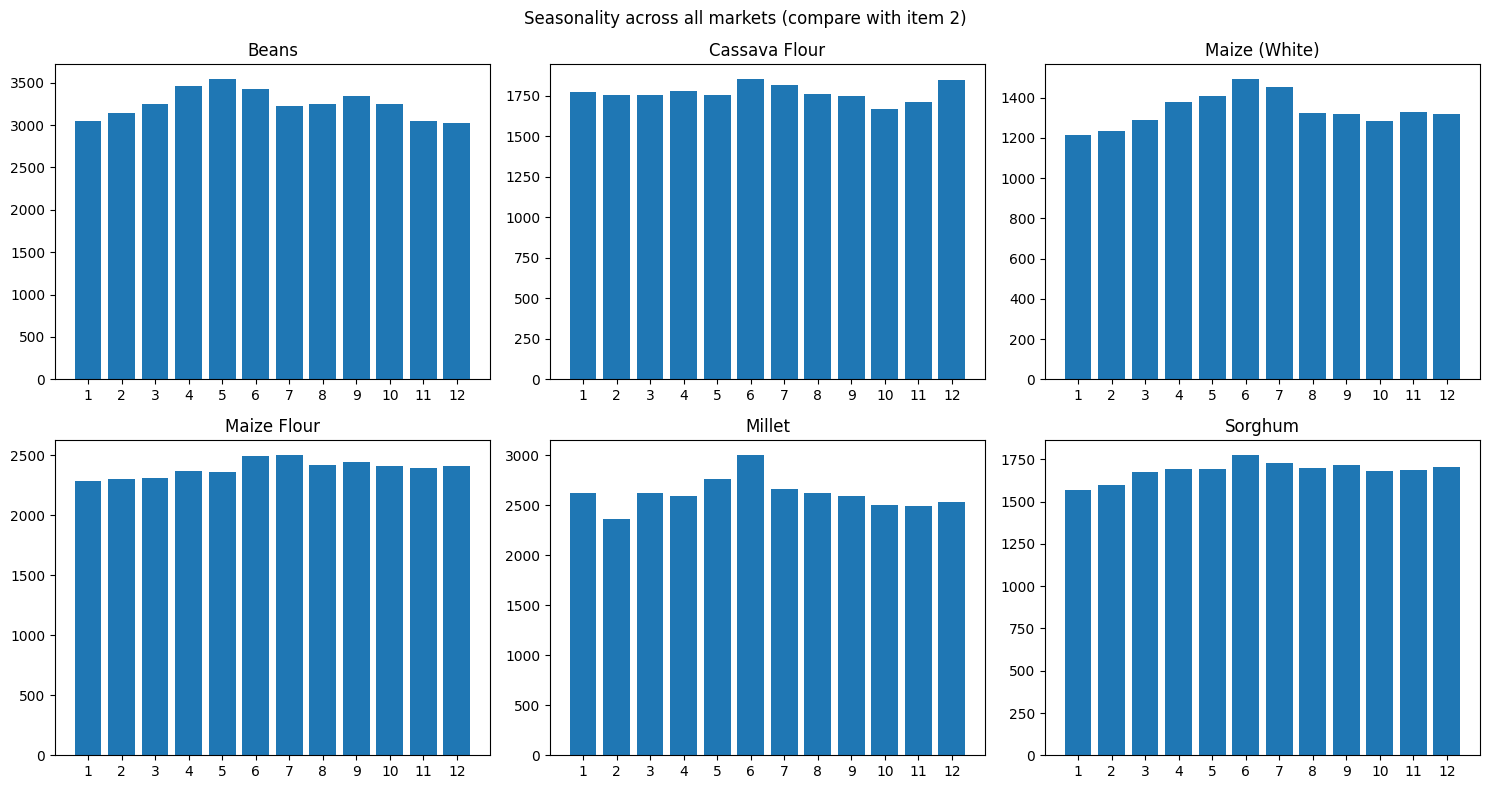

In [ ]:
wide_core_crops = data[data[Crop].isin(crops)].copy()
wide_core_crops['month'] = wide_core_crops[Date].dt.month

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, crop in zip(axes.flat, crops):
    monthly_avg = wide_core_crops[wide_core_crops[Crop] == crop].groupby('month')[Price].mean()
    ax.bar(monthly_avg.index, monthly_avg.values)
    ax.set_title(crop)
    ax.set_xticks(range(1, 13))

plt.suptitle('Seasonality across all markets (compare with item 2)')
plt.tight_layout()
plt.show()


## 20. Temperature vs. Price by Commodity

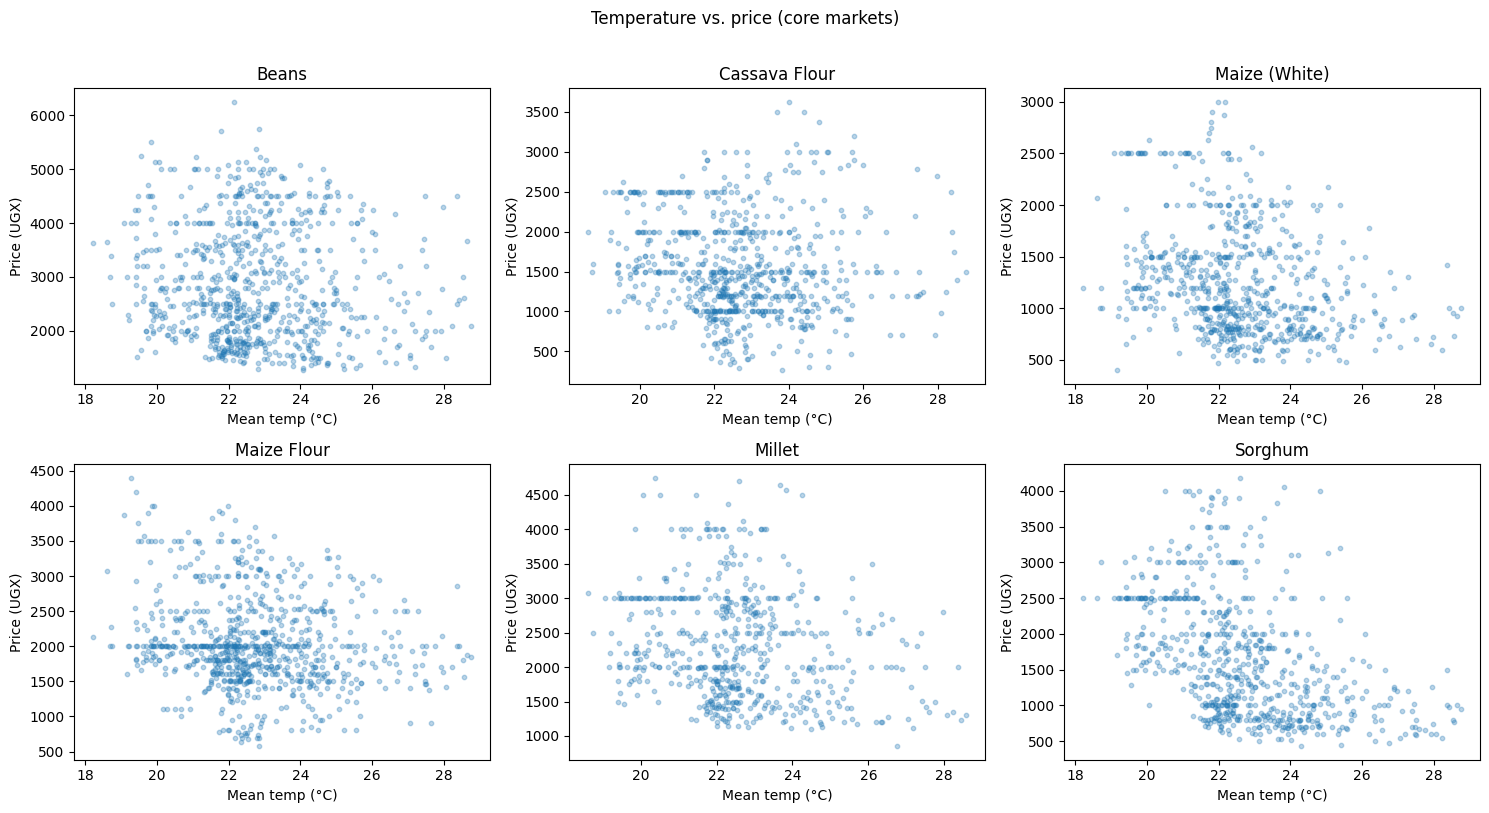

In [ ]:
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, crop in zip(axes.flat, crops):
    sub = core[core[Crop] == crop].dropna(subset=['temp_mean_c', Price])
    ax.scatter(sub['temp_mean_c'], sub[Price], alpha=0.3, s=10)
    ax.set_title(crop)
    ax.set_xlabel('Mean temp (°C)')
    ax.set_ylabel('Price (UGX)')

plt.suptitle('Temperature vs. price (core markets)', y=1.01)
plt.tight_layout()
plt.show()


## 21. Interactive Price Snapshot (beans)


In [ ]:
try:
    import plotly.express as px

    crop_pick_g = 'Beans'
    crop_data = data[data[Crop] == crop_pick_g]
    latest_g = crop_data[Date].max()
    snapshot_g = crop_data[crop_data[Date] == latest_g]

    fig = px.scatter_geo(
        snapshot_g, lat=Latitude, lon=Longitude, size=Price, color=Price,
        hover_name=Market, color_continuous_scale='OrRd', scope='africa',
        title=f'{crop_pick_g} price snapshot -- {latest_g.date()}',
    )
    fig.update_geos(center=dict(lat=1.5, lon=32.5), projection_scale=6, showcountries=True)
    fig.show()
except ImportError:
    print("plotly is not installed in this environment -- run 'pip install plotly' to use this cell.")


#Sorghum price snapshot

In [ ]:
import plotly.express as px

crop_choice = 'Sorghum'

crop_map_data = data[(data['commodity'] == crop_choice) & (data['date'] == '2025-12-15') & (data['forecastable'] == True)].copy()
print(crop_map_data[['market', 'latitude', 'longitude', 'price']])

fig = px.scatter_geo(
    crop_map_data,
    lat='latitude',
    lon='longitude',
    size='price',
    color='price',
    hover_name='market',
    color_continuous_scale='OrRd',
    scope='africa',
    title=f'{crop_choice} Price Snapshot — December 2025',
    size_max=30
)

fig.update_geos(
    center=dict(lat=1.5, lon=32.5),
    projection_scale=6,
    showcountries=True
)

fig.show()

        market  latitude  longitude   price
20157   Iganga      0.61      33.47  1844.0
20291     Lira      2.23      32.91   920.0
20307  Mbarara     -0.61      30.65  3944.0


#Cassava flour price snapshot

In [ ]:
import plotly.express as px

crop_choice = 'Cassava Flour'

crop_map_data = data[(data['commodity'] == crop_choice) & (data['date'] == '2025-12-15') & (data['forecastable'] == True)].copy()
print(crop_map_data[['market', 'latitude', 'longitude', 'price']])

fig = px.scatter_geo(
    crop_map_data,
    lat='latitude',
    lon='longitude',
    size='price',
    color='price',
    hover_name='market',
    color_continuous_scale='OrRd',
    scope='africa',
    title=f'{crop_choice} Price Snapshot — December 2025',
    size_max=30
)

fig.update_geos(
    center=dict(lat=1.5, lon=32.5),
    projection_scale=6,
    showcountries=True
)

fig.show()

        market  latitude  longitude   price
20153   Iganga      0.61      33.47  1300.0
20184    Jinja      0.42      33.20  1500.0
20287     Lira      2.23      32.91  2200.0
20303  Mbarara     -0.61      30.65  1933.0


#Maize (white) price snapshot

In [ ]:
import plotly.express as px

crop_choice = 'Maize (White)'

crop_map_data = data[(data['commodity'] == crop_choice) & (data['date'] == '2025-12-15') & (data['forecastable'] == True)].copy()
print(crop_map_data[['market', 'latitude', 'longitude', 'price']])

fig = px.scatter_geo(
    crop_map_data,
    lat='latitude',
    lon='longitude',
    size='price',
    color='price',
    hover_name='market',
    color_continuous_scale='OrRd',
    scope='africa',
    title=f'{crop_choice} Price Snapshot — December 2025',
    size_max=30
)

fig.update_geos(
    center=dict(lat=1.5, lon=32.5),
    projection_scale=6,
    showcountries=True
)

fig.show()

        market  latitude  longitude   price
20154   Iganga      0.61      33.47  1533.0
20185    Jinja      0.42      33.20  1863.0
20288     Lira      2.23      32.91   920.0
20304  Mbarara     -0.61      30.65  2467.0


#Maize flour price snapshot

In [ ]:
import plotly.express as px

crop_choice = 'Maize Flour'

crop_map_data = data[(data['commodity'] == crop_choice) & (data['date'] == '2025-12-15') & (data['forecastable'] == True)].copy()
print(crop_map_data[['market', 'latitude', 'longitude', 'price']])

fig = px.scatter_geo(
    crop_map_data,
    lat='latitude',
    lon='longitude',
    size='price',
    color='price',
    hover_name='market',
    color_continuous_scale='OrRd',
    scope='africa',
    title=f'{crop_choice} Price Snapshot — December 2025',
    size_max=30
)

fig.update_geos(
    center=dict(lat=1.5, lon=32.5),
    projection_scale=6,
    showcountries=True
)

fig.show()

        market  latitude  longitude   price
20155   Iganga      0.61      33.47  2078.0
20186    Jinja      0.42      33.20  2000.0
20289     Lira      2.23      32.91  1740.0
20305  Mbarara     -0.61      30.65  3011.0


#A piechart for the most expensive and cheap market

###considering the average of all commodities and all the years

###importing libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

###filtering the markets

In [ ]:
pie_data = data[data['market'].isin(['Owino', 'Iganga', 'Jinja', 'Mbarara', 'Lira'])].copy()

###calculating the average price per market

In [ ]:
market_avg_price5 = pie_data.groupby('market')['price'].mean().reset_index()
print(market_avg_price5)

    market        price
0   Iganga  1754.075834
1    Jinja  1974.392900
2     Lira  1603.998350
3  Mbarara  2264.659079
4    Owino  1932.151804


###building the piechart

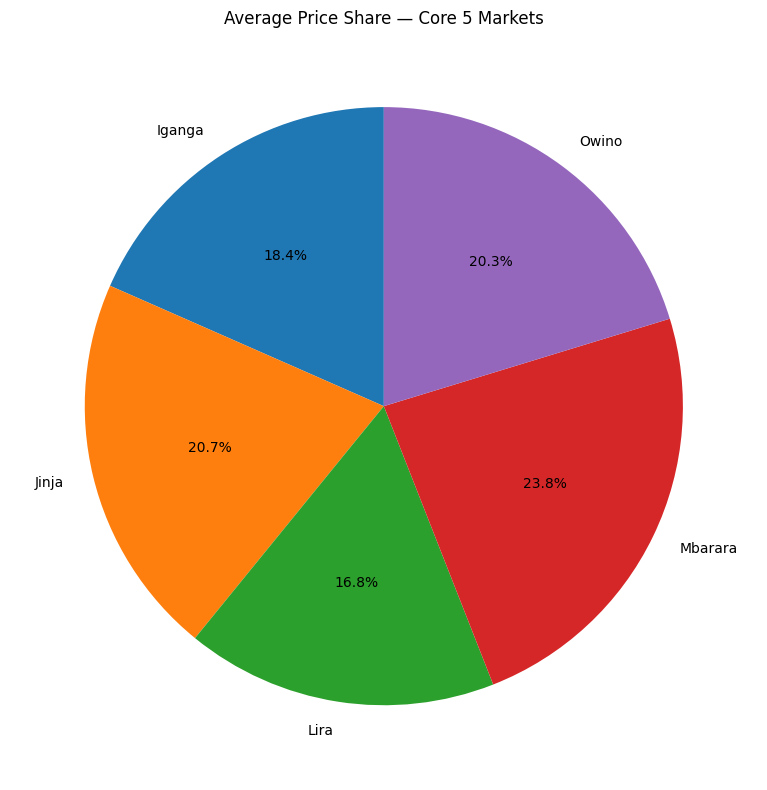

In [ ]:
plt.figure(figsize=(8, 8))
plt.pie(
    market_avg_price5['price'],
    labels=market_avg_price5['market'],
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Average Price Share — Core 5 Markets')
plt.tight_layout()
plt.show()

#average annual price of beans in owino market

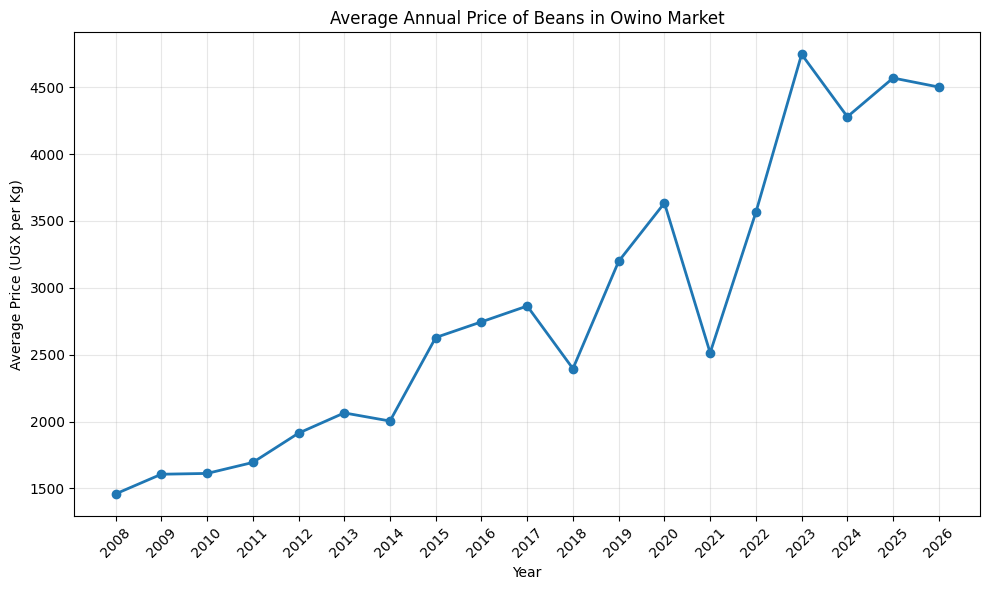

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('market_data_with_weather.csv')

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Extract year
df['year'] = df['date'].dt.year

# Filter for Owino market and Beans
beans_owino = df[(df['market'] == 'Owino') & (df['commodity'] == 'Beans')]

# Group by year and get average price
yearly_avg = beans_owino.groupby('year')['price'].mean().reset_index()

# Plot
plt.figure(figsize=(10, 6))
plt.plot(yearly_avg['year'], yearly_avg['price'], marker='o', linewidth=2)
plt.title('Average Annual Price of Beans in Owino Market')
plt.xlabel('Year')
plt.ylabel('Average Price (UGX per Kg)')
plt.grid(True, alpha=0.3)
plt.xticks(yearly_avg['year'], rotation=45)
plt.tight_layout()
plt.show()

#average annual rainfall in owino market

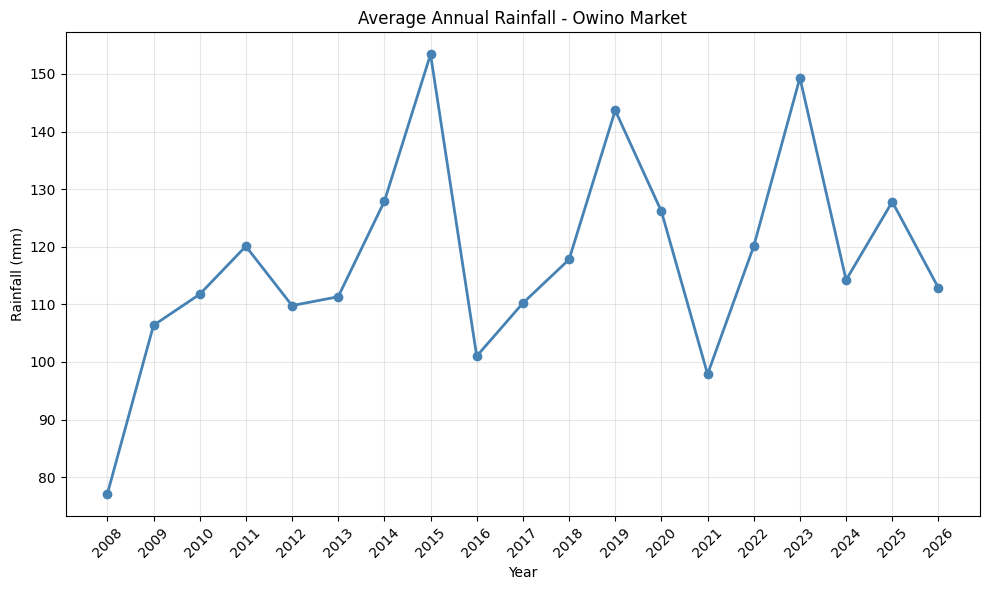

In [ ]:
# Group rainfall by year (same beans_owino filtered dataframe)
yearly_rainfall = beans_owino.groupby('year')['rainfall_mm'].mean().reset_index()

# Plot
plt.figure(figsize=(10, 6))
plt.plot(yearly_rainfall['year'], yearly_rainfall['rainfall_mm'], marker='o', color='steelblue', linewidth=2)
plt.title('Average Annual Rainfall - Owino Market')
plt.xlabel('Year')
plt.ylabel('Rainfall (mm)')
plt.grid(True, alpha=0.3)
plt.xticks(yearly_rainfall['year'], rotation=45)
plt.tight_layout()
plt.show()

#graphs of price of beans and rainfall in owino market 2023

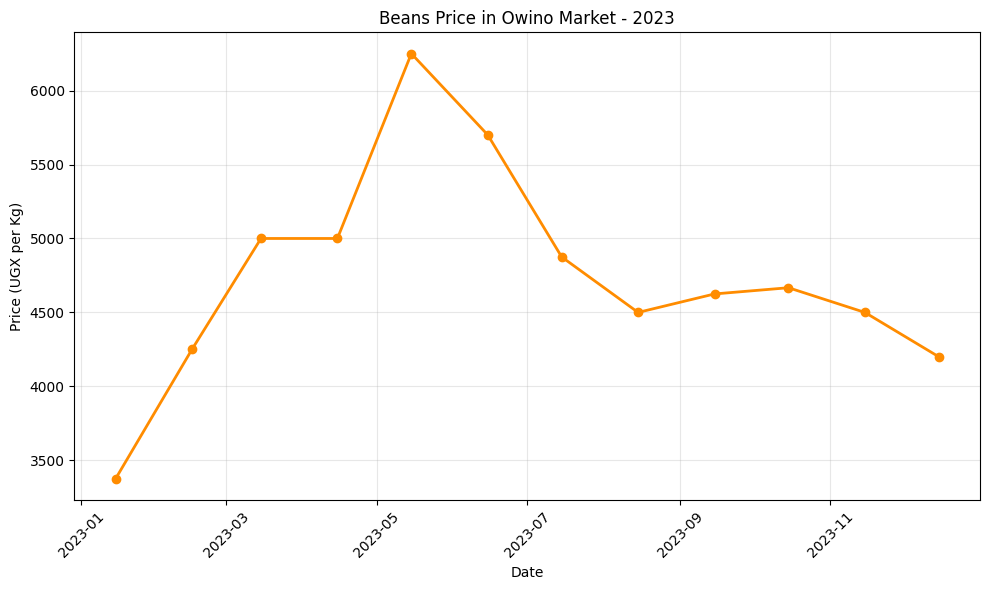

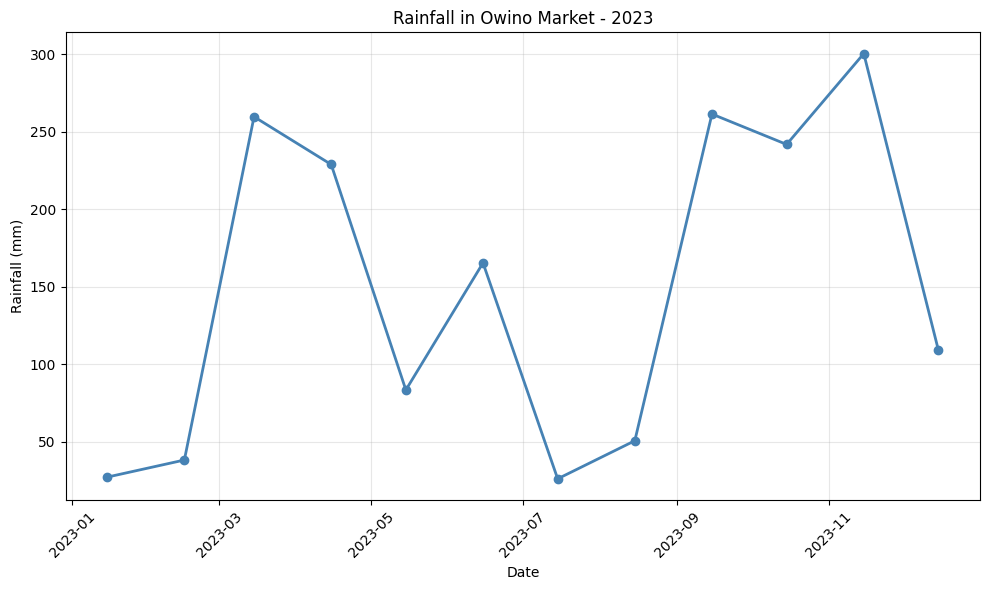

In [ ]:
# Choose the year you want to look at
selected_year = 2023

# Filter for that specific year (using beans_owino from before)
year_data = beans_owino[beans_owino['year'] == selected_year].sort_values('date')

# --- Plot 1: Price against date ---
plt.figure(figsize=(10, 6))
plt.plot(year_data['date'], year_data['price'], marker='o', color='darkorange', linewidth=2)
plt.title(f'Beans Price in Owino Market - {selected_year}')
plt.xlabel('Date')
plt.ylabel('Price (UGX per Kg)')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Plot 2: Rainfall against date ---
plt.figure(figsize=(10, 6))
plt.plot(year_data['date'], year_data['rainfall_mm'], marker='o', color='steelblue', linewidth=2)
plt.title(f'Rainfall in Owino Market - {selected_year}')
plt.xlabel('Date')
plt.ylabel('Rainfall (mm)')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#a heatmapshowing the correlation of rainfall, price and date for all commodities in all markets

In [ ]:
# Convert date to a numeric value so it can be correlated
df['date_numeric'] = df['date'].map(pd.Timestamp.toordinal)

# Select the three columns of interest
corr_data = df[['date_numeric', 'rainfall_mm', 'price']]

# Compute correlation matrix
corr_matrix = corr_data.corr()

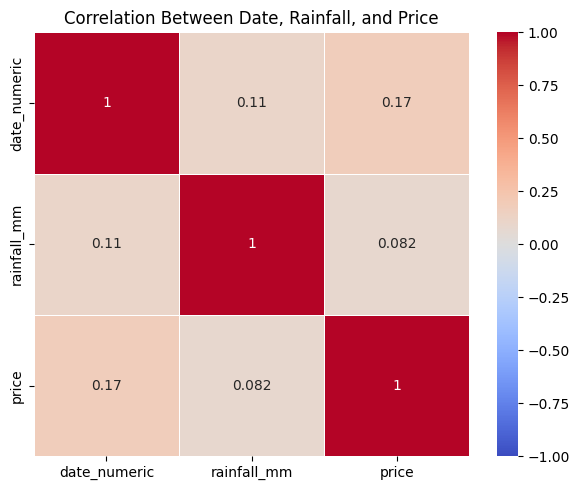

In [ ]:
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Between Date, Rainfall, and Price')
plt.tight_layout()
plt.show()

#a heatmap showing the relationship of rainfall, prices and date for beans in owino market

In [ ]:
# Add date_numeric to beans_owino (if not already present)
beans_owino['date_numeric'] = beans_owino['date'].map(pd.Timestamp.toordinal)

# Select the three columns of interest
corr_data_beans = beans_owino[['date_numeric', 'rainfall_mm', 'price']]

# Compute correlation matrix
corr_matrix_beans = corr_data_beans.corr()

/tmp/ipykernel_2916/3652887319.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



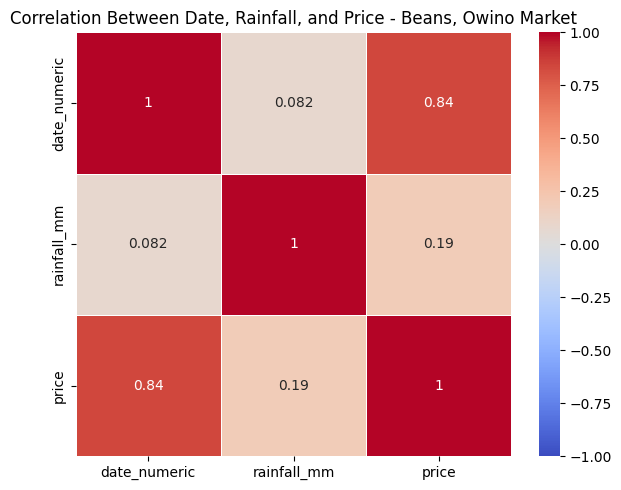

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix_beans, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Between Date, Rainfall, and Price - Beans, Owino Market')
plt.tight_layout()
plt.show()